# E-Commerce Returns Analysis & Dashboard

This notebook connects to our MongoDB database to analyze E-commerce transaction logs using **Advanced Aggregation Pipelines** and visualizes the insights using **Matplotlib**.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from pymongo import MongoClient

# Connect to MongoDB (Replace with your Atlas URI)
connection_string = "mongodb://localhost:27017/"
try:
    client = MongoClient(connection_string, serverSelectionTimeoutMS=2000)
    db = client['ecommerce_db']
    # Test connection
    client.server_info()
    connected = True
    print("Successfully connected to MongoDB!")
except:
    connected = False
    print("Could not connect to MongoDB. Falling back to CSV data for analysis.")

Could not connect to MongoDB. Falling back to CSV data for analysis.


## 1. Advanced MongoDB Aggregation: Return Rate by Category
We want to find out which product category has the highest return rate. We will use MongoDB's `$group` and `$match` operators.

In [8]:
if connected:
    pipeline = [
        # Group by category and calculate total purchases and total returns
        {
            "$group": {
                "_id": "$product_category",
                "total_purchases": {
                    "$sum": { "$cond": [ { "$eq": [ "$event_type", "purchase" ] }, 1, 0 ] }
                },
                "total_returns": {
                    "$sum": { "$cond": [ { "$eq": [ "$event_type", "return" ] }, 1, 0 ] }
                }
            }
        },
        # Add a field for return rate
        {
            "$addFields": {
                "return_rate": { "$divide": [ "$total_returns", "$total_purchases" ] }
            }
        },
        # Sort by highest return rate
        {
            "$sort": { "return_rate": -1 }
        }
    ]
    
    # Execute the query
    results = list(db.events.aggregate(pipeline))
    df_returns = pd.DataFrame(results)
    df_returns = df_returns.rename(columns={"_id": "category"})
else:
    # Fallback to Pandas if Mongo is not running
    df = pd.read_csv('cleaned_events.csv')
    purchases = df[df['event_type'] == 'purchase'].groupby('product_category').size()
    returns = df[df['event_type'] == 'return'].groupby('product_category').size()
    
    df_returns = pd.DataFrame({'total_purchases': purchases, 'total_returns': returns}).reset_index()
    df_returns = df_returns.rename(columns={'product_category': 'category'})
    df_returns['return_rate'] = df_returns['total_returns'] / df_returns['total_purchases']
    df_returns = df_returns.sort_values('return_rate', ascending=False)

print("Insight Discovered:")
print(df_returns.head())

Insight Discovered:
      category  total_purchases  total_returns  return_rate
0      Apparel             1898            601     0.316649
2  Electronics             2053            105     0.051145
3         Home             1989            100     0.050277
1       Beauty             2060             99     0.048058


## 2. Dashboarding: Visualizing the Problem (Matplotlib)
Now we will create a dashboard view (similar to what you would build in Metabase/Redash) to visualize the problem.

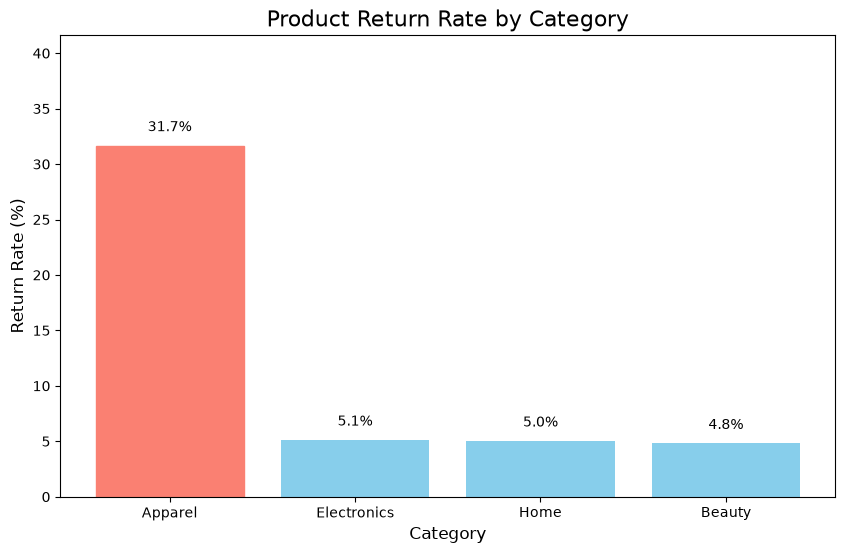

BUSINESS INSIGHT: Apparel is suffering from a massive return rate. We need to investigate sizing guides.


In [9]:
plt.figure(figsize=(10, 6))

# Create a bar chart showing Return Rate by Category
bars = plt.bar(df_returns['category'], df_returns['return_rate'] * 100, color='skyblue')

# Highlight the worst performing category in Red
bars[0].set_color('salmon') 

plt.title('Product Return Rate by Category', fontsize=16)
plt.xlabel('Category', fontsize=12)
plt.ylabel('Return Rate (%)', fontsize=12)
plt.ylim(0, max(df_returns['return_rate'] * 100) + 10)

# Add percentage labels on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1, f'{yval:.1f}%', ha='center', va='bottom')

plt.show()

print("BUSINESS INSIGHT: Apparel is suffering from a massive return rate. We need to investigate sizing guides.")